# 09. 가을야구 성적 — 정규시즌 모델은 가을에도 통할까?

안녕하세요! **KBO 승패 예측 프로젝트의 아홉 번째 이야기**예요. 짝이 되는 코드는 `src/kbo_predict/postseason_eval.py`예요.

**이 노트북이 하는 일**
- 2018~2026 **포스트시즌 경기만** 따로 모아, 정규시즌 경기로만 배운 승패 모델이 가을야구에서 얼마나 맞히는지 재요.
- 세 가지 방식을 비교해요: 지금 방식(v0.3, 정규시즌 끝 전력으로 고정), 가을야구 결과를 전력에 넣어 가는 방식, 시리즈 전망에 쓰는 팀 모델.
- 경기 단위(적중률·log loss)와 **시리즈 단위**(시리즈 시작 전에 더 높게 본 팀이 실제로 이겼나)로 채점해요.
- 2026 한국시리즈 전에 **경기 예측은 KT, 시리즈 전망은 삼성**으로 엇갈린 이유를 요인별로 풀어 봐요.

**왜 하나요?**
- 2026 가을야구에서 v0.3은 14경기 중 5경기만 맞혔어요. 한국시리즈는 1차전만 맞히고 2~5차전 네 경기를 연달아 틀렸어요(삼성 4승 1패 우승).
- 모델은 정규시즌 경기로만 배웠고, 가을야구 경기 결과는 전력에 넣지 않아요. "가을에는 모델이 망가지는 걸까?"를 한 시즌이 아니라 여러 시즌으로 확인하려는 거예요.

## 1. 준비

- 이 노트북은 `notebooks/` 폴더에서 실행되니까, 한 단계 위가 프로젝트 루트예요. `src/`를 파이썬 경로에 넣어 `kbo_predict`를 불러와요.
- `KBO_DATA_DIR` 환경변수로 데이터 폴더(`data/`)를 알려 줘요. `raw_store`가 이 값을 보고 경기·박스스코어 파일을 찾아요.
- 결과 파일 `data/public/postseason_report.json`(명령줄 `python -m kbo_predict.postseason_eval`이 만든 것)도 읽어 둬요. 4번에서 다시 계산해 같은지 확인해요.

In [1]:
import copy
import json
import logging
import os
import sys
import time
import warnings
from pathlib import Path

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")          # scikit-learn이 코어 수를 찾다 내는 경고를 막아요
warnings.filterwarnings("ignore")                          # 라이브러리 버전·수렴 안내 메시지는 숨겨요 (계산에는 영향 없음)

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter

T0 = time.time()                                           # 노트북 전체 실행 시간을 재기 시작
ROOT = Path.cwd().parent                                   # notebooks/의 한 단계 위 = 프로젝트 루트
sys.path.insert(0, str(ROOT / "src"))                      # kbo_predict 패키지를 불러오기 위해
os.environ["KBO_DATA_DIR"] = str(ROOT / "data")            # raw_store가 경기·박스스코어 파일을 찾는 폴더 (01·02번과 같아요)

from kbo_predict import postseason_eval as pe              # 가을야구 성적 (이 노트북의 짝)
from kbo_predict import raw_store
from kbo_predict.features import FACTOR_LABELS, game_features, load_features
from kbo_predict.predict import raw_prob
from kbo_predict.rewind import state_before
from kbo_predict.train_win import explain, load_bundle

# 그래프 한글 폰트와 모양 (03·08번과 같아요)
plt.rcParams["font.family"] = ["Malgun Gothic", "AppleGothic", "NanumGothic", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)  # 없는 후보 폰트 안내 메시지는 숨겨요
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e5e4e0", "axes.axisbelow": True})
BLUE, ORANGE, GRAY, INK = "#2a78d6", "#e07b39", "#b8b6b0", "#52514e"
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 60)

df = load_features(ROOT / "data" / "processed" / "features.parquet")
report = json.loads((ROOT / "data" / "public" / "postseason_report.json").read_text(encoding="utf-8"))
KO = report["candidates"]                                   # 방식 세 개의 한글 이름
TEAM_KO = {"OB": "두산", "LT": "롯데", "KT": "KT", "WO": "키움", "SK": "SSG", "SS": "삼성", "HH": "한화", "HT": "KIA", "LG": "LG", "NC": "NC"}
print(f"결과 파일 만든 시각 {report['generated_at']} · 계산에 걸린 시간 {report['elapsed_sec']}초")

결과 파일 만든 시각 2026-11-09T15:18:38+09:00 · 계산에 걸린 시간 5.5초


## 2. 가을야구 경기 모으기

`postseason_games(시즌)`은 **정규시즌 마지막 경기일 뒤의 끝난 경기**를 모아요(무승부·점수 없는 경기는 빼요).
같은 두 팀의 연속 맞대결을 **시리즈 하나**로 묶어요. 한 가을에 같은 두 팀은 한 번만 만나니까 이렇게 묶을 수 있어요.

In [2]:
rows = []
for s in report["seasons"]:
    post = pe.postseason_games(s)
    ser = [x for x in report["series"] if x["season"] == s]
    rows.append({"시즌": s, "가을야구 경기": len(post), "시리즈": len(ser),
                 "홈팀 승률": report["by_season"][str(s)]["home_win_rate"],
                 "우승 팀": TEAM_KO[ser[-1]["winner"]] if ser else "-"})
games_tbl = pd.DataFrame(rows).set_index("시즌")
display(games_tbl.style.format({"홈팀 승률": "{:.1%}"}))
print(f"합계 {games_tbl['가을야구 경기'].sum()}경기 (2018~2025 {games_tbl.loc[2018:2025, '가을야구 경기'].sum()}경기 + 2026 {games_tbl.loc[2026, '가을야구 경기']}경기)")

,가을야구 경기,시리즈,홈팀 승률,우승 팀
시즌,,,,
2018,16,4,62.5%,SSG
2019,12,4,58.3%,두산
2020,13,4,53.8%,NC
2021,12,5,33.3%,KT
2022,16,4,68.8%,SSG
2023,14,4,35.7%,LG
2024,16,4,62.5%,KIA
2025,16,4,62.5%,LG
2026,14,4,71.4%,삼성


합계 129경기 (2018~2025 115경기 + 2026 14경기)


**해석:** 가을야구는 한 해 12~16경기뿐이에요. 2018~2025 여덟 시즌을 합쳐도 **115경기**, 정규시즌 한 시즌(약 700경기)의 6분의 1이에요.
그래서 이 노트북의 숫자는 몇 %p 차이로 "어느 방식이 낫다"고 말하기 어려워요. 그 점을 계속 기억하면서 볼게요.

## 3. 비교하는 방식과 채택 규칙

모든 방식은 08번처럼 **그 시즌보다 앞선 시즌들로만 학습**해요(미래를 본 모델은 없어요).

| 방식 | 모델 | 전력(리그 상태) |
|---|---|---|
| 지금 방식 (`frozen`) | v0.3 설정: L1 로지스틱 + Elo, 피처 27개, 실제 선발 기록 | 정규시즌 마지막 날로 고정 |
| 가을야구 결과 반영 (`in_state`) | 같은 모델 | 가을 경기 결과를 그날그날 넣어 감 (휴식일 차이만 지금 방식 값 — 9번) |
| 팀 모델 (`team`) | 시리즈 전망용: L2 로지스틱, 팀 피처 19개 (선발·Elo 없음) | 정규시즌 마지막 날로 고정 |

**채택 규칙** (2026-11-09에 정함): 가을야구 결과 반영 방식을 라이브에 쓰려면, 2018~2025 포스트시즌 log loss가 지금 방식보다 낮고
경기별 log loss 차이의 대응표본 t 검정이 **p < 0.05**여야 해요.
**정직하게 적을 점:** 이 규칙은 2026 가을야구 결과와 예비 계산을 **본 뒤에** 정했어요.

In [3]:
print("채택 규칙:", report["protocol"]["adopt_rule"])
print("정한 때:", report["protocol"]["rule_declared"])
display(pd.DataFrame({"방식": list(KO), "이름": list(KO.values())}).set_index("방식"))

채택 규칙: in_state를 쓰려면 2018~2025 포스트시즌 log loss가 frozen보다 낮고 대응표본 t 검정 p < 0.05
정한 때: 2026-11-09 (2026 가을야구 결과와 예비 계산을 본 뒤)


,이름
방식,
frozen,"지금 방식 (v0.3, 정규시즌 끝 전력으로 고정)"
in_state,"가을야구 결과 반영 (v0.3, 가을 경기로 전력 갱신)"
team,시리즈 전망용 팀 모델 (선발·Elo 없음)


## 4. 다시 계산해서 결과 파일과 같은지 확인

`pe.run(df)`가 명령줄과 똑같은 계산을 해요. 아홉 시즌마다 모델 둘(승패·팀)을 새로 학습하고 가을 경기를 예측해요.
결과 파일의 주요 숫자(합친 성적, 시리즈 성적, 2026 경기별 확률, 결정)가 그대로 나오는지 비교해요.

In [4]:
rerun = pe.run(df, history_path=ROOT / "data" / "public" / "history.csv", log=lambda *_: None)
rerun = json.loads(json.dumps(rerun, ensure_ascii=False))
for key in ("by_season", "pooled", "series_summary", "games_2026", "decision", "live_2026"):
    print(f"{key:15s} 결과 파일과 같나요? {rerun[key] == report[key]}")

by_season       결과 파일과 같나요? True
pooled          결과 파일과 같나요? True
series_summary  결과 파일과 같나요? True
games_2026      결과 파일과 같나요? True
decision        결과 파일과 같나요? True
live_2026       결과 파일과 같나요? True


**해석:** 모두 `True`면 사이트 성적표의 "가을야구 성적" 숫자는 이 노트북의 계산과 같아요. 로지스틱 회귀는 무작위성이 없어서 다시 계산해도 같은 값이 나와요.

## 5. 경기 단위 성적 — 적중률과 log loss

- **적중률**: 50%보다 높게 본 팀이 이긴 비율이에요.
- **log loss**(확률 오차): 확률을 얼마나 잘 매겼는지 보는 점수예요. 낮을수록 좋고, 모든 경기를 50%로 찍으면 0.6931이에요.
- 비교용 규칙 두 개: 항상 홈팀, 정규시즌 승률이 높은 팀.

In [5]:
P = report["pooled"]
tbl = []
for m in pe.MODELS:
    tbl.append({"방식": KO[m], "2018~2025 적중률": P["dev"][m]["accuracy"], "2018~2025 log loss": P["dev"][m]["log_loss"],
                "2026 적중률": P["test"][m]["accuracy"], "2026 log loss": P["test"][m]["log_loss"]})
for r, name in report["rules"].items():
    tbl.append({"방식": f"규칙: {name}", "2018~2025 적중률": P["dev"][f"rule_{r}"]["accuracy"], "2026 적중률": P["test"][f"rule_{r}"]["accuracy"]})
display(pd.DataFrame(tbl).set_index("방식").style.format({c: "{:.1%}" for c in ("2018~2025 적중률", "2026 적중률")} | {
    c: "{:.4f}" for c in ("2018~2025 log loss", "2026 log loss")}, na_rep="—"))
t = P["dev"]["tests"]
print(f"[2018~2025] 가을 결과 반영 vs 지금: log loss 차이 {t['in_state_vs_frozen']['logloss_gain']:+.4f} (p = {t['in_state_vs_frozen']['logloss_p']:.3f})")
print(f"[2018~2025] 팀 모델 vs 지금: 적중 McNemar p = {t['team_vs_frozen']['mcnemar_p']:.3f}, log loss 차이 {t['team_vs_frozen']['logloss_gain']:+.4f}")
print(f"[2018~2025] 지금 vs 정규시즌 승률 규칙: McNemar p = {t['frozen_vs_rule_better_record']['mcnemar_p']:.3f}")

,2018~2025 적중률,2018~2025 log loss,2026 적중률,2026 log loss
방식,,,,
"지금 방식 (v0.3, 정규시즌 끝 전력으로 고정)",59.1%,0.6764,35.7%,0.7003
"가을야구 결과 반영 (v0.3, 가을 경기로 전력 갱신)",60.0%,0.6774,35.7%,0.7005
시리즈 전망용 팀 모델 (선발·Elo 없음),55.6%,0.6842,57.1%,0.6709
규칙: 항상 홈팀,55.6%,—,71.4%,—
규칙: 정규시즌 승률이 높은 팀,55.6%,—,57.1%,—


[2018~2025] 가을 결과 반영 vs 지금: log loss 차이 -0.0010 (p = 0.430)
[2018~2025] 팀 모델 vs 지금: 적중 McNemar p = 0.523, log loss 차이 -0.0077
[2018~2025] 지금 vs 정규시즌 승률 규칙: McNemar p = 0.627


**해석:**
- **2018~2025 가을야구에서 지금 방식은 59.1%**를 맞혔어요. 08번의 정규시즌 성적(2018~2026 57.9%)과 비슷해요. **가을이라고 모델이 망가지는 건 아니에요.**
- 그런데 규칙(55.6%)과의 차이도, 팀 모델(55.6%)과의 차이도 p값이 0.5 안팎이라 **우연과 구분되지 않아요.** 115경기로는 이 정도 차이를 가려낼 수 없어요.
- 가을야구 결과 반영 방식은 적중률은 60.0%로 조금 높지만 log loss는 오히려 0.001 나빠졌어요(p = 0.43). **채택 규칙을 넘지 못해서 지금 방식을 유지해요.**
- 2026은 지금 방식 35.7%(5/14)로 나빴고, 팀 모델이 57.1%로 더 나았어요. 하지만 14경기는 너무 적어서 이것만으로 팀 모델이 낫다고 할 수 없어요.

## 6. 시즌별로 보기

**출력 보는 법:** 파란 굵은 선 = 지금 방식, 회색 선 = 팀 모델, 주황 점선 = 정규시즌 승률이 높은 팀 규칙. 점 하나가 한 시즌(12~16경기)이에요.

,지금 방식,팀 모델,규칙: 정규시즌 승률,경기 수
2018,62.5%,43.8%,43.8%,16
2019,66.7%,58.3%,66.7%,12
2020,53.8%,61.5%,53.8%,13
2021,58.3%,33.3%,50.0%,12
2022,56.2%,68.8%,56.2%,16
2023,50.0%,42.9%,57.1%,14
2024,68.8%,62.5%,62.5%,16
2025,56.2%,68.8%,56.2%,16
2026,35.7%,57.1%,57.1%,14


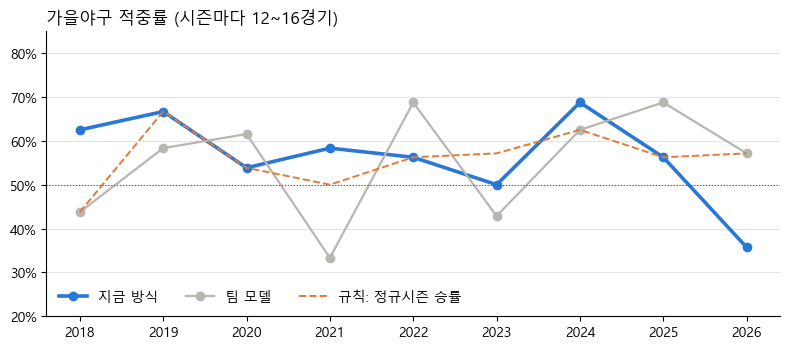

In [6]:
seasons = report["seasons"]
per = pd.DataFrame({
    "지금 방식": [report["by_season"][str(s)]["frozen"]["accuracy"] for s in seasons],
    "팀 모델": [report["by_season"][str(s)]["team"]["accuracy"] for s in seasons],
    "규칙: 정규시즌 승률": [report["by_season"][str(s)]["rule_better_record"]["accuracy"] for s in seasons],
    "경기 수": [report["by_season"][str(s)]["n"] for s in seasons]}, index=seasons)
display(per.style.format({c: "{:.1%}" for c in per.columns if c != "경기 수"}))
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(seasons, per["지금 방식"], color=BLUE, lw=2.6, marker="o", label="지금 방식")
ax.plot(seasons, per["팀 모델"], color=GRAY, lw=1.6, marker="o", label="팀 모델")
ax.plot(seasons, per["규칙: 정규시즌 승률"], color=ORANGE, lw=1.4, ls="--", label="규칙: 정규시즌 승률")
ax.axhline(0.5, color=INK, lw=0.8, ls=":")
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0)); ax.set_ylim(0.2, 0.85)
ax.set_title("가을야구 적중률 (시즌마다 12~16경기)", loc="left"); ax.legend(frameon=False, ncol=3, loc="lower left")
plt.tight_layout(); plt.show()

**해석:** 시즌마다 50%에서 69%까지 크게 출렁여요. 경기가 적으면 한두 경기로 몇 %p가 바뀌기 때문이에요.
2026(35.7%)은 아홉 시즌 중 가장 낮지만, 2023(50.0%)처럼 낮은 해가 전에도 있었어요. 어느 방식도 모든 해에 앞서지 않아요.

## 7. 시리즈 단위 — 시작 전 우세 팀이 이겼나?

각 시리즈 첫날, **선발을 모르는 상태**로 두 팀의 승리 확률을 내요. 어느 구장이든 같은 비중으로 보려고
"A 홈일 때 A 승" 확률과 "B 홈일 때 A 승" 확률을 평균해요. 50%보다 높게 본 팀을 "시작 전 우세 팀"으로 정하고, 실제 시리즈 승자와 비교해요.

In [7]:
srows = []
for x in report["series"]:
    a, b = x["teams"]
    srows.append({"시즌": x["season"], "시리즈": x["name"], "두 팀 (앞 = 정규시즌 승률 높은 팀)": f"{TEAM_KO[a]} vs {TEAM_KO[b]}",
                  "전적": f"{x['wins'][0]}-{x['wins'][1]}", "승자": TEAM_KO[x["winner"]],
                  "지금 방식": f"{TEAM_KO[x['picks']['frozen']]} ({max(x['p_first']['frozen'], 1 - x['p_first']['frozen']):.0%})",
                  "팀 모델": f"{TEAM_KO[x['picks']['team']]} ({max(x['p_first']['team'], 1 - x['p_first']['team']):.0%})"})
display(pd.DataFrame(srows).tail(8))
S = report["series_summary"]
for lab, key in (("2018~2025", "dev"), ("2026", "test"), ("전체", "all")):
    s = S[key]
    print(f"{lab}: 시리즈 {s['n']}개 — 지금 방식 {s['frozen']}개, 가을 결과 반영 {s['in_state']}개, 팀 모델 {s['team']}개, 정규시즌 승률 규칙 {s['rule_better_record']}개 맞힘")

,시즌,시리즈,두 팀 (앞 = 정규시즌 승률 높은 팀),전적,승자,지금 방식,팀 모델
29,2025,1번째 시리즈,삼성 vs NC,1-1,NC,삼성 (52%),삼성 (56%)
30,2025,2번째 시리즈,SSG vs 삼성,1-3,삼성,삼성 (51%),삼성 (53%)
31,2025,3번째 시리즈,한화 vs 삼성,3-2,한화,한화 (52%),한화 (53%)
32,2025,4번째 시리즈,LG vs 한화,4-1,LG,LG (56%),LG (59%)
33,2026,와일드카드,LG vs 두산,1-0,LG,LG (51%),LG (53%)
34,2026,준플레이오프,KIA vs LG,3-0,KIA,KIA (51%),LG (53%)
35,2026,플레이오프,삼성 vs KIA,3-2,삼성,삼성 (51%),삼성 (54%)
36,2026,한국시리즈,KT vs 삼성,1-4,삼성,KT (52%),삼성 (51%)


2018~2025: 시리즈 33개 — 지금 방식 21개, 가을 결과 반영 21개, 팀 모델 20개, 정규시즌 승률 규칙 19개 맞힘
2026: 시리즈 4개 — 지금 방식 3개, 가을 결과 반영 3개, 팀 모델 3개, 정규시즌 승률 규칙 3개 맞힘
전체: 시리즈 37개 — 지금 방식 24개, 가을 결과 반영 24개, 팀 모델 23개, 정규시즌 승률 규칙 22개 맞힘


**해석:**
- 시리즈 37개 중 지금 방식이 24개(65%), 팀 모델이 23개를 맞혔어요. 거의 같아요.
- 눈여겨볼 점은 **시작 전 확률이 대부분 50~56%**라는 거예요. 모델이 보기에 가을야구에 올라온 팀들은 전력 차이가 작아요. 그래서 시리즈 결과는 그날그날의 경기력과 운에 크게 흔들려요.
- 2026 한국시리즈: 지금 방식은 KT(52%), 팀 모델은 삼성(51%)을 골랐어요. 둘 다 사실상 반반이었고, 결과는 삼성 4승 1패였어요.

## 8. 2026 한국시리즈 — 두 계산은 왜 엇갈렸나?

사이트의 **경기 예측**은 승패 모델(v0.3, `win_model.pkl`)이, **시리즈 전망**은 팀 모델(`team-2026.pkl`)이 계산해요.
한국시리즈 1차전 날(11/3)의 같은 상태에서 **선발 없이** KT 홈 경기를 두 모델이 어떻게 봤는지, 확률을 움직인 요인 상위 5개를 비교해요.
기여도(로짓)가 +면 홈팀 KT 쪽, −면 삼성 쪽으로 밀었다는 뜻이에요.

In [8]:
win, team = load_bundle(ROOT / "models" / "win_model.pkl"), load_bundle(ROOT / "models" / "team-2026.pkl")
st = state_before(2026, "2026-11-03")
g = {"home_code": "KT", "away_code": "SS", "date": "2026-11-03", "season": 2026, "game_id": 0}
f = game_features(g, st, None)
for name, b in (("승패 모델 (경기 예측)", win), ("팀 모델 (시리즈 전망)", team)):
    X = pd.DataFrame([{k: f[k] for k in b["features"]}], columns=b["features"])
    contrib, base = explain(b, X)
    top = sorted(zip(b["features"], contrib[0]), key=lambda t: -abs(t[1]))[:5]
    p_home = raw_prob(b, g, st, None)
    print(f"{name}: P(KT 홈 승) = {p_home:.1%}")
    display(pd.DataFrame([{"요인": FACTOR_LABELS.get(k, k), "값 (KT − 삼성)": round(float(f[k]), 3), "기여도(로짓)": round(float(v), 3)} for k, v in top]).set_index("요인"))

승패 모델 (경기 예측): P(KT 홈 승) = 54.4%


,값 (KT − 삼성),기여도(로짓)
요인,,
Elo 전력 점수 차이,63.048,0.130
타선 삼진 비율 차이,0.012,-0.024
타선 홈런 비율 차이,-0.004,-0.017
선발 9이닝당 삼진 차이,NaN,-0.002
최근 3일 불펜 투구수 차이,0.000,0.001


팀 모델 (시리즈 전망): P(KT 홈 승) = 51.3%


,값 (KT − 삼성),기여도(로짓)
요인,,
최근 10경기 흐름,0.600,-0.049
시즌 진행도,1.000,0.047
홈팀의 홈 경기 승률,0.652,-0.037
타선 삼진 비율 차이,0.012,-0.032
팀 승률 차이,0.059,0.032


**해석:**
- **승패 모델**은 거의 **Elo 전력 점수 하나**로 KT 쪽에 섰어요(KT가 63점 높음). Elo는 여러 시즌 경기 결과로 쌓은 점수라, 정규시즌을 압도한 KT(승률 .647)를 꾸준히 높게 봐요.
- **팀 모델**은 Elo가 없어요. 시즌 진행도·팀 승률 차이는 KT 쪽으로 밀었지만, 최근 10경기 흐름과 홈팀의 홈 경기 승률은 삼성 쪽으로 밀었어요. (최근 10경기는 KT가 더 좋았는데도, 이 모델은 다른 팀 기록과 함께 볼 때 이 요인을 반대 방향으로 쓰도록 배웠어요.) 그래서 KT 홈 경기도 반반에 가깝게(51%) 봤고, 삼성 홈 경기에서는 삼성을 55%로 봐서 시리즈 전체로는 삼성이 조금 앞섰어요.
- 한 사이트 안에서 두 모델이 다른 팀을 고르면 보는 사람이 헷갈려요. 이번 시험에서 둘 중 확실히 나은 쪽은 없었어요(5번 p = 0.52). 그래서 **어느 쪽으로 합칠지는 이 결과만으로 정하지 않고 다음 과제로 남겨요.**

## 9. 휴식일 함정 — 가을 결과를 그대로 넣으면 생기는 일

처음 예비 계산에서 "가을야구 결과 반영"이 log loss를 0.007 줄여 좋아 보였어요. 그런데 시리즈 시작 전 확률을 보니 **한국시리즈 직행 팀 우세가 79%**까지 커져 있었어요(아래는 지금 라이브 모델로 같은 상황을 다시 계산한 것이라 숫자가 조금 달라요).
원인은 **휴식일 차이**예요. 가을 경기로 상태를 갱신하면 직행 팀은 20일 넘게 쉰 것으로, 상대는 하루 이틀 쉰 것으로 계산돼요.
정규시즌 학습 데이터에서 휴식일 차이는 대부분 −2~+2일이라, 모델은 처음 보는 큰 값을 그대로 늘려 해석했어요. 아래에서 그 차이를 직접 봐요.

In [9]:
games = raw_store.load_games(2026); boxes = raw_store.load_boxscores(2026)
frozen = state_before(2026, "2026-11-03", games=games, boxscores=boxes)   # 정규시즌 끝 상태 (지금 방식)
live = copy.deepcopy(frozen)
for x in pe.postseason_games(2026, games):
    if x["date"] < "2026-11-03":
        live.update(x, boxes.get(x["game_id"]))         # 와일드카드~플레이오프 결과를 전력에 넣기
f_live, f_frozen = game_features(g, live, None), game_features(g, frozen, None)
print(f"휴식일 차이 (KT − 삼성): 고정 상태 {f_frozen['rest_diff']:+.0f}일 → 가을 결과를 넣은 상태 {f_live['rest_diff']:+.0f}일")
print(f"학습 데이터의 휴식일 차이: 1% 지점 {df['rest_diff'].quantile(0.01):+.0f}일, 99% 지점 {df['rest_diff'].quantile(0.99):+.0f}일")
print(f"P(KT 홈 승): 그대로 넣으면 {raw_prob(win, g, live, None):.1%}, 휴식일만 고정 값으로 바꾸면 {pe._in_state_p(win, g, live, frozen, None):.1%}, 지금 방식 {raw_prob(win, g, frozen, None):.1%}")

휴식일 차이 (KT − 삼성): 고정 상태 +0일 → 가을 결과를 넣은 상태 +20일
학습 데이터의 휴식일 차이: 1% 지점 -2일, 99% 지점 +2일
P(KT 홈 승): 그대로 넣으면 77.4%, 휴식일만 고정 값으로 바꾸면 54.4%, 지금 방식 54.4%


**해석:** 휴식일 차이가 학습 범위를 훨씬 넘어서자 확률이 크게 튀었어요. 이건 "가을 흐름"이 아니라 **학습 범위 밖으로 넘겨 짚은 것(외삽)**이에요.
그래서 `in_state`는 휴식일 차이만 지금 방식 값을 쓰도록 고쳤고, 고친 뒤에는 개선 효과가 사라졌어요(5번).
처음 보인 개선은 모델이 좋아진 게 아니라 이 함정 때문이었어요. 숫자가 좋아 보여도 확률을 직접 들여다봐야 하는 이유예요.

## 10. 정직하게 적어 둘 점과 결론

**정직하게 적어 둘 점**
1. 채택 규칙은 2026 가을야구 결과를 본 뒤에 정했어요.
2. 가을야구는 115경기(+2026 14경기)뿐이라 몇 %p 차이는 우연과 구분되지 않아요.
3. 사이트에 실제로 공개한 2026 가을 예측은 10/29부터 8경기(4경기 적중)예요. 이 노트북의 2026 숫자는 "그 시즌보다 앞선 시즌들로만 학습"해 다시 계산한 값이라 공개 기록과 조금 달라요.
4. 시리즈 단위 비교는 선발을 모르는 상태의 평균 확률이에요. 실제 시리즈 전망(1만 번 가상 경기)과는 계산 방법이 달라요.

**결론**
- 정규시즌 모델은 가을야구에서도 **2018~2025 59.1%**로 정규시즌과 비슷하게 맞혔어요. 가을에 따로 망가지지 않아요.
- 2026 가을의 부진(5/14, 한국시리즈 4연속 실패)은 모델이 거의 반반(43~59%)으로 본 경기에서 이변이 이어진 결과예요. 모델 확률대로라면 5경기 이하가 나올 확률은 약 12%예요.
- 가을야구 결과를 전력에 넣는 방식은 휴식일 함정을 고치고 나니 나아지지 않았어요. **지금 방식을 유지해요.**
- 경기 예측(Elo 중심)과 시리즈 전망(팀 기록 중심)이 엇갈릴 수 있다는 점은 사이트 성적표에 그대로 적었어요. 하나로 합치는 일은 다음 과제예요.

In [10]:
print(f"노트북 전체 실행 시간: {time.time() - T0:.0f}초")

노트북 전체 실행 시간: 9초
